# LPILE & GROUP-Style Laterally Loaded Pile Analysis in Python

Nonlinear **$p$-$y$ beam-column FEM** solver for single piles and coupled **2D finite-element pile-cap groups**, modeled on **Ensoft LPILE** and **GROUP**.

### Governing Mechanics
$$EI(z)\frac{d^4 y}{dz^4} + P_x\frac{d^2 y}{dz^2} + E_s(z, y)\,y = 0, \qquad p(z, y) = E_s(z, y)\,y$$

### Quick Input Reference (US Customary Units)
| Soil `"type"` | Required Keys | Optional Keys (with Defaults) | Typical Ranges |
| :--- | :--- | :--- | :--- |
| **`"soft_clay"`** *(Matlock 1970)* | `gamma_pcf`, `cu_psf` | `eps50` (`0.020`), `J` (`0.50`) | $c_u$: 250–1,000 psf · $\varepsilon_{50}$: 0.010–0.020 |
| **`"stiff_clay"`** *(Reese-Welch 1975)* | `gamma_pcf`, `cu_psf` | `eps50` (`0.007`), `J` (`0.50`) | $c_u$: 1,000–4,000 psf · $\varepsilon_{50}$: 0.004–0.007 |
| **`"reese_sand"`** *(Reese 1974)* | `gamma_pcf`, `phi_deg` | `k_pci` *(auto from $\phi$ & GWL)* | $\phi$: 28°–40° · $k$: 20–225 pci |
| **`"api_sand"`** *(API RP 2A)* | `gamma_pcf`, `phi_deg` | `k_pci` *(auto from $\phi$ & GWL)* | $\phi$: 28°–40° · $k$: 20–250 pci |
| **`"weak_rock"`** *(Reese 1997)* | `gamma_pcf`, `qu_psi`, `E_ir_ksi` | `rqd_pct` (`50`), `k_rm` (`0.0005`) | $q_u$: 200–2,000 psi · $E_{ir}$: 15–200 ksi |

*Tip: Omit `top_ft` in `SOIL_LAYERS` and each layer automatically starts where the previous layer ends! Just specify `thickness_ft` (or `bottom_ft`).*

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.inputs import (
    build_pile_section,
    build_soil_profile,
    pile_summary_table,
    soil_profile_table,
)
from src.py_curves import APISand, ReeseSand, LinearWinklerSoil, SoilLayer, SoilProfile
from src.sections import CustomPileSection
from src.solver import BoundaryCondition, solve_lateral_pile, run_pushover
from src.group import PileCapSpec, GroupPileSpec, CapLoadCase, solve_pile_group
from src.plotting import (
    plot_input_schematic,
    plot_lpile_4panel,
    plot_py_curves,
    plot_pushover_curves,
    plot_pile_cap_response,
    plot_group_load_sharing,
)

pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 135)
pd.set_option("display.float_format", "{:.2f}".format)

## 1. User Input Dashboard — Edit Your Pile, Soil Profile & Loads Here

Change any values in the cell below and re-run the notebook (`Run All`) to analyze your own pile and site stratigraphy.

✓ Inputs validated! Echoing Pile & Soil Tables below:


,Value
Property,
Section Name,Steel Pipe 24.0 in x 0.500 in
"Embedded Length, L",60.0 ft (720 in)
"Diameter / Width, b",24.00 in (2.00 ft)
"Cross-Sectional Area, A",36.91 in²
"Moment of Inertia, I","2,549.4 in⁴"
"Elastic Modulus, E","29,000.0 ksi"
"Flexural Stiffness, EI","73,931,247 kip·in² (513,411 kip·ft²)"
"Elastic Yield Moment, My",885.2 kip·ft


,Name,Depth (ft),Thickness (ft),p-y Model,γ (pcf),Key Parameters,p-Mult,σ'v at Bottom (psf)
Layer #,,,,,,,,
1,Soft Marine Clay,0.0 – 15.0,15.00,Soft Clay (Matlock),110.00,"cu=600 psf, ε50=0.020, J=0.50",1.00,1088.40
2,Med. Dense Sand,15.0 – 35.0,20.00,Sand (Reese 1974),122.00,"φ=34.0°, k=73 pci (auto)",1.00,2280.40
3,Stiff Clay,35.0 – 50.0,15.00,Stiff Clay (Reese-Welch),125.00,"cu=2500 psf, ε50=0.007, J=0.50",1.00,3219.40
4,Weathered Shale,50.0 – 70.0,20.00,Weak Rock (Reese 1997),140.00,"qu=500 psi, Eir=50 ksi, RQD=60%",1.00,4771.40


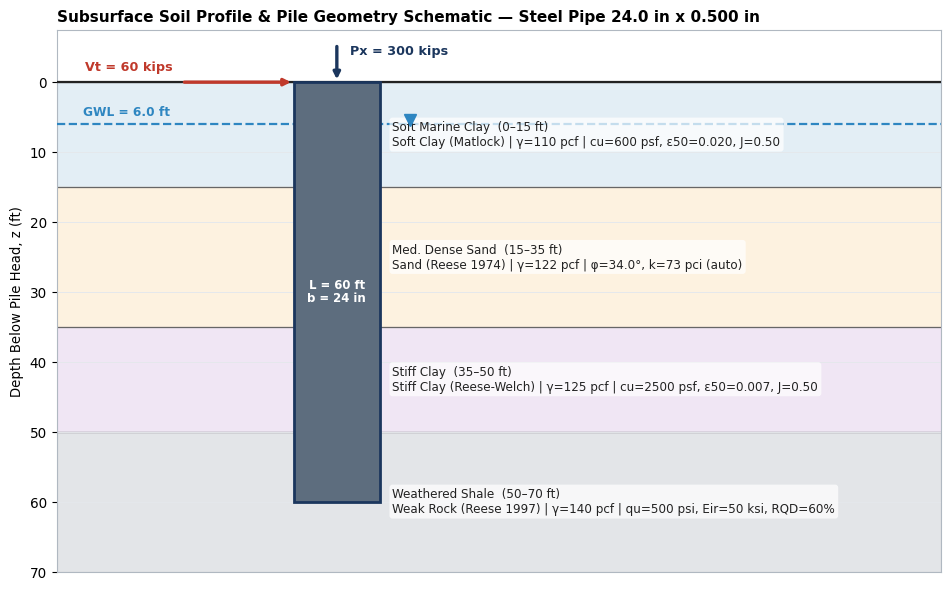

In [2]:
# ==============================================================================
# A. PILE CROSS-SECTION & EMBEDDED LENGTH
#    Switch "type" to: "steel_pipe", "drilled_shaft", "h_pile", or "custom"
# ==============================================================================
PILE_LENGTH_FT = 60.0  # Total embedded pile length below head (ft)

PILE_CONFIG = {
    "type": "steel_pipe",         # Circular hollow steel pipe pile
    "diameter_in": 24.0,          # Outer diameter, D (in)
    "wall_thickness_in": 0.50,    # Wall thickness, t (in)
    "E_ksi": 29000.0,             # Young's modulus of steel (ksi)
    "fy_ksi": 50.0,               # Yield strength Fy (ksi) -> computes yield moment My
}

# Alternative examples (uncomment any block to swap sections):
# PILE_CONFIG = {"type": "drilled_shaft", "diameter_in": 36.0, "fc_ksi": 4.0, "cracked_factor": 0.50}
# PILE_CONFIG = {"type": "h_pile", "depth_in": 14.0, "flange_width_in": 14.5, "area_in2": 21.4, "inertia_in4": 729.0, "strong_axis": True}

# ==============================================================================
# B. SUBSURFACE SOIL STRATIGRAPHY & GROUNDWATER TABLE
#    Layers stack automatically from z = 0 downward using thickness_ft (or bottom_ft)
# ==============================================================================
GROUNDWATER_DEPTH_FT = 6.0  # Depth to water table below pile head (ft)

SOIL_LAYERS = [
    {
        "name": "Soft Marine Clay",
        "type": "soft_clay",      # Matlock (1970)
        "thickness_ft": 15.0,     # z = 0 to 15 ft
        "gamma_pcf": 110.0,       # Total unit weight (pcf)
        "cu_psf": 600.0,          # Undrained shear strength c_u (psf)
        "eps50": 0.020,           # Strain at 50% max stress
    },
    {
        "name": "Med. Dense Sand",
        "type": "reese_sand",     # Reese, Cox & Koop (1974) — or try "api_sand"
        "thickness_ft": 20.0,     # z = 15 to 35 ft
        "gamma_pcf": 122.0,       # Total unit weight (pcf)
        "phi_deg": 34.0,          # Friction angle (degrees); k_pci auto-computed
    },
    {
        "name": "Stiff Clay",
        "type": "stiff_clay",     # Reese & Welch (1975)
        "thickness_ft": 15.0,     # z = 35 to 50 ft
        "gamma_pcf": 125.0,       # Total unit weight (pcf)
        "cu_psf": 2500.0,         # Undrained shear strength c_u (psf)
        "eps50": 0.007,
    },
    {
        "name": "Weathered Shale",
        "type": "weak_rock",      # Reese (1997)
        "thickness_ft": 20.0,     # z = 50 to 70 ft
        "gamma_pcf": 140.0,       # Unit weight (pcf)
        "qu_psi": 500.0,          # Uniaxial compressive strength (psi)
        "E_ir_ksi": 50.0,         # Initial rock mass modulus (ksi)
        "rqd_pct": 60.0,          # Rock Quality Designation (%)
    },
]

# ==============================================================================
# C. SINGLE-PILE DESIGN LOADS & PILE-GROUP CAP CONFIGURATION
# ==============================================================================
SINGLE_PILE_LOADS = {
    "lateral_load_kips": 60.0,    # Applied head shear, Vt (kips)
    "moment_kip_ft": 0.0,         # Applied head moment, Mt (kip-ft)
    "axial_load_kips": 300.0,     # Compressive axial load, Px (kips, triggers P-Delta)
    "cap_spring_kip_in_rad": 5.0e5,  # Semi-rigid pile-cap rotational spring (kip-in/rad)
}

GROUP_CONFIG = {
    "row_x_positions_ft": [-6.0, 0.0, +6.0],  # 3 rows at 6 ft (3B) center-to-center spacing
    "piles_per_row": 3,                       # 3x3 = 9 total piles
    "cap_thickness_ft": 5.0,                  # Concrete cap depth (ft)
    "cap_width_ft": 16.0,                     # Out-of-plane cap width (ft)
    "cap_overhang_ft": 2.0,                   # Edge overhang beyond outer rows (ft)
    "cap_fc_ksi": 4.0,                        # Concrete f'c (ksi)
    "lateral_load_kips": 360.0,               # Total group shear H (kips)
    "vertical_load_kips": 1800.0,             # Total group vertical load V (kips)
    "moment_kip_ft": 2400.0,                  # Total group overturning moment M (kip-ft)
}

# Build validated objects from the clean input dictionaries
pile = build_pile_section(PILE_CONFIG)
soil = build_soil_profile(SOIL_LAYERS, gwl_ft=GROUNDWATER_DEPTH_FT)
V_DESIGN = SINGLE_PILE_LOADS["lateral_load_kips"]
M_DESIGN = SINGLE_PILE_LOADS["moment_kip_ft"]
P_AXIAL = SINGLE_PILE_LOADS["axial_load_kips"]

print("✓ Inputs validated! Echoing Pile & Soil Tables below:")
display(pile_summary_table(pile, PILE_LENGTH_FT))
display(soil_profile_table(soil))

fig = plot_input_schematic(
    pile,
    PILE_LENGTH_FT,
    soil,
    bc=BoundaryCondition(head="free", lateral_load_kips=V_DESIGN, moment_kip_ft=M_DESIGN, axial_load_kips=P_AXIAL),
)
plt.show()

## 2. Generated Nonlinear $p$-$y$ Curves Across Depth

Inspect the generated $p$-$y$ resistance curves $p(z, y)$ (kips/ft) across all soil/rock strata before running the pile solver.

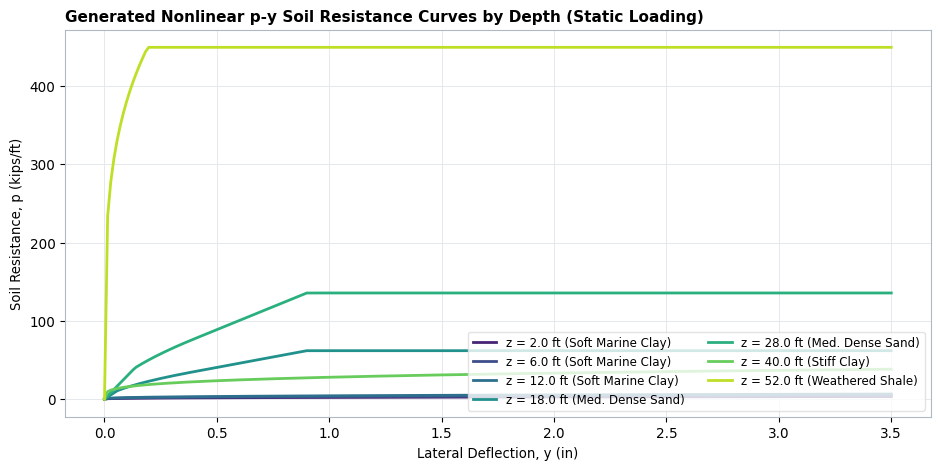

In [3]:
depths_inspect = [2.0, 6.0, 12.0, 18.0, 28.0, 40.0, 52.0]
fig = plot_py_curves(soil, pile, depths_ft=depths_inspect, y_max_in=3.5, loading="static")
plt.show()

## 3. Single-Pile Analysis: Free-Head vs. Fixed-Head vs. Semi-Rigid Pile Cap

Applies your `SINGLE_PILE_LOADS` (`Vt`, `Mt`, `Px`) across three pile-head rotational restraint conditions.

,Head Defl. y₀ (in),Head Slope θ₀ (rad),Head Moment (kip-ft),Max Moment (kip-ft),Depth M_max (ft),Moment DCR (|M|/My),Equil. ∫p dz / Vt,Iters
Head Condition,,,,,,,,
Free Head,2.89,-0.02,0.00,592.91,15.60,0.67,1.00,31
Fixed Head (θ₀=0),0.69,0.00,-476.26,-476.26,0.00,0.54,1.00,28
Semi-Rigid Cap,1.50,-0.01,-288.47,344.98,16.00,0.39,1.00,29


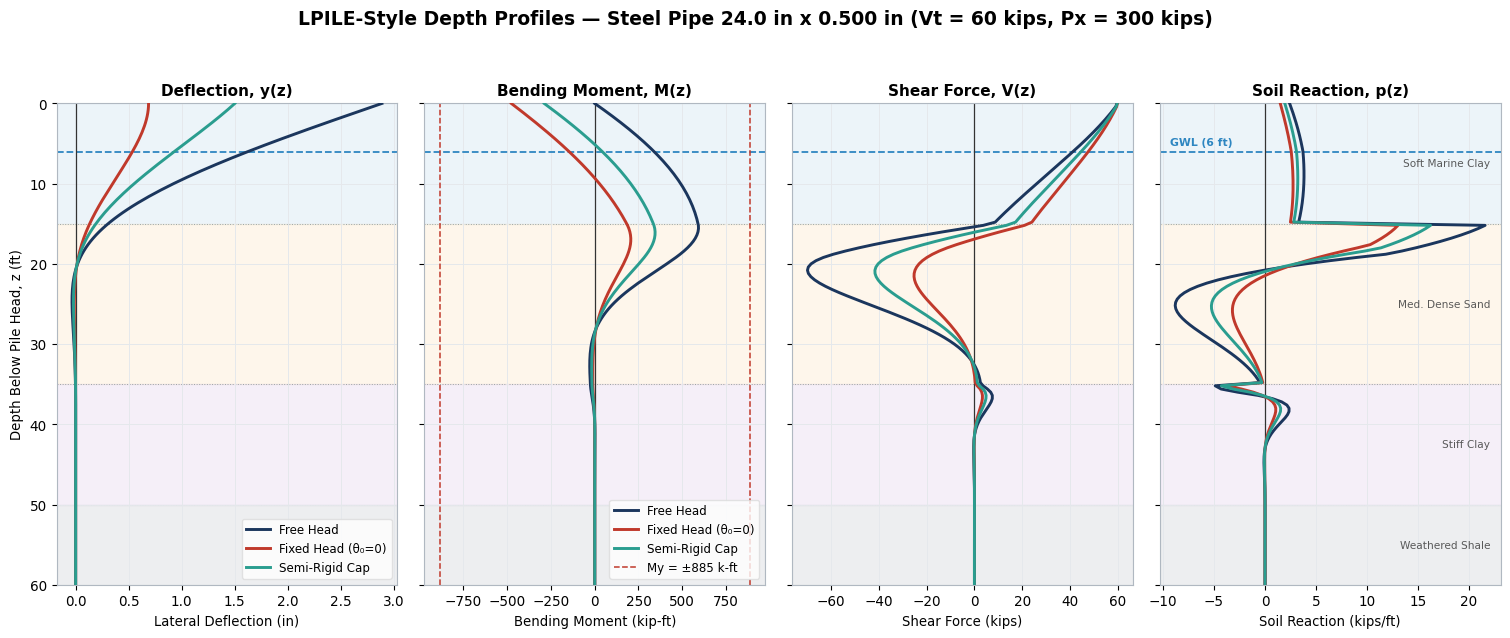

In [4]:
cases = {
    "Free Head": BoundaryCondition(
        head="free", lateral_load_kips=V_DESIGN, moment_kip_ft=M_DESIGN, axial_load_kips=P_AXIAL
    ),
    "Fixed Head (θ₀=0)": BoundaryCondition(
        head="fixed", lateral_load_kips=V_DESIGN, axial_load_kips=P_AXIAL
    ),
    "Semi-Rigid Cap": BoundaryCondition(
        head="spring",
        lateral_load_kips=V_DESIGN,
        moment_kip_ft=M_DESIGN,
        axial_load_kips=P_AXIAL,
        head_rotational_stiffness_kip_in_per_rad=SINGLE_PILE_LOADS["cap_spring_kip_in_rad"],
    ),
}

results = {
    name: solve_lateral_pile(pile, PILE_LENGTH_FT, soil, bc, loading="static", n_elements=150)
    for name, bc in cases.items()
}

summary_rows = []
for name, res in results.items():
    p_int = float(np.trapezoid(res.profile["p_kips_per_ft"], res.profile["z_ft"]))
    dcr = abs(res.max_moment_kip_ft) / pile.yield_moment_kip_ft if pile.yield_moment_kip_ft else np.nan
    summary_rows.append({
        "Head Condition": name,
        "Head Defl. y₀ (in)": res.head_deflection_in,
        "Head Slope θ₀ (rad)": res.head_slope_rad,
        "Head Moment (kip-ft)": res.head_moment_kip_ft,
        "Max Moment (kip-ft)": res.max_moment_kip_ft,
        "Depth M_max (ft)": res.depth_max_moment_ft,
        "Moment DCR (|M|/My)": dcr,
        "Equil. ∫p dz / Vt": p_int / max(abs(V_DESIGN), 1e-6),
        "Iters": res.iterations,
    })

display(pd.DataFrame(summary_rows).set_index("Head Condition"))

fig = plot_lpile_4panel(
    results,
    soil=soil,
    pile=pile,
    title=f"LPILE-Style Depth Profiles — {pile.name} (Vt = {V_DESIGN:.0f} kips, Px = {P_AXIAL:.0f} kips)",
)
plt.show()

## 4. Static vs. Cyclic Loading & Axial $P$-$\Delta$ Sensitivity

,Head Defl. y₀ (in),Max Moment (kip-ft),Depth M_max (ft),Moment DCR (|M|/My)
Case,,,,
"Static, Px = 0",5.04,984.29,16.00,1.11
"Static, Px = 500 kips (P-Δ)",6.06,1177.90,16.00,1.33
"Cyclic, Px = 500 kips (P-Δ)",6.50,1235.89,16.00,1.40


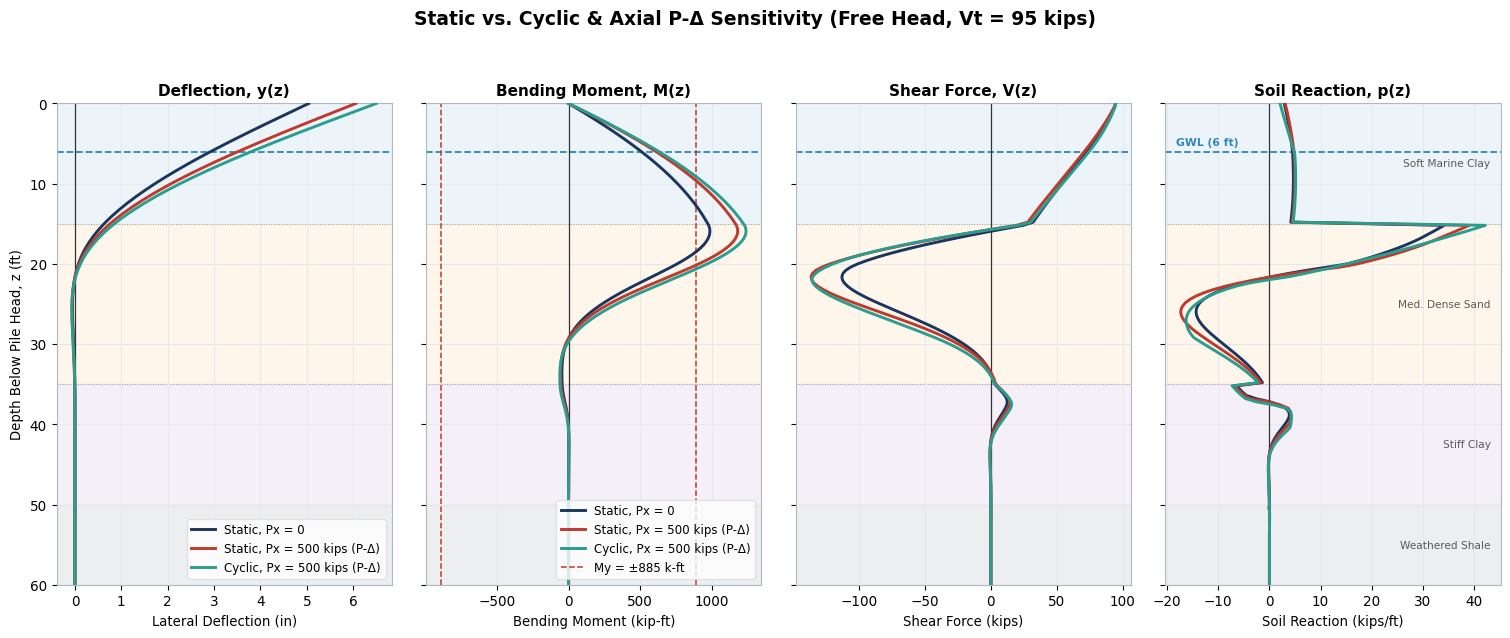

In [5]:
V_HEAVY = 95.0
sens_results = {
    "Static, Px = 0": solve_lateral_pile(
        pile, PILE_LENGTH_FT, soil,
        BoundaryCondition(head="free", lateral_load_kips=V_HEAVY, axial_load_kips=0.0),
        loading="static", n_elements=150,
    ),
    "Static, Px = 500 kips (P-Δ)": solve_lateral_pile(
        pile, PILE_LENGTH_FT, soil,
        BoundaryCondition(head="free", lateral_load_kips=V_HEAVY, axial_load_kips=500.0),
        loading="static", n_elements=150,
    ),
    "Cyclic, Px = 500 kips (P-Δ)": solve_lateral_pile(
        pile, PILE_LENGTH_FT, soil,
        BoundaryCondition(head="free", lateral_load_kips=V_HEAVY, axial_load_kips=500.0),
        loading="cyclic", n_elements=150,
    ),
}

sens_tbl = pd.DataFrame([
    {
        "Case": name,
        "Head Defl. y₀ (in)": res.head_deflection_in,
        "Max Moment (kip-ft)": res.max_moment_kip_ft,
        "Depth M_max (ft)": res.depth_max_moment_ft,
        "Moment DCR (|M|/My)": abs(res.max_moment_kip_ft) / pile.yield_moment_kip_ft if pile.yield_moment_kip_ft else np.nan,
    }
    for name, res in sens_results.items()
]).set_index("Case")
display(sens_tbl)

fig = plot_lpile_4panel(
    sens_results,
    soil=soil,
    pile=pile,
    title=f"Static vs. Cyclic & Axial P-Δ Sensitivity (Free Head, Vt = {V_HEAVY:.0f} kips)",
)
plt.show()

## 5. Lateral Pushover Analysis & Drilled Shaft Comparison

,Load at y₀ = 1.0 in (kips),|M_max| at y₀ = 1.0 in (kip-ft),y₀ at Vt = 100 kips (in),|M_max| at Vt = 100 kips (kip-ft)
Foundation Option,,,,
"24"" Active Pile (Free Head)",30.12,221.96,6.13,1171.17
"24"" Active Pile (Fixed Head)",77.22,646.46,1.43,876.57
"36"" Drilled Shaft (Free Head)",44.61,373.54,3.36,1112.74


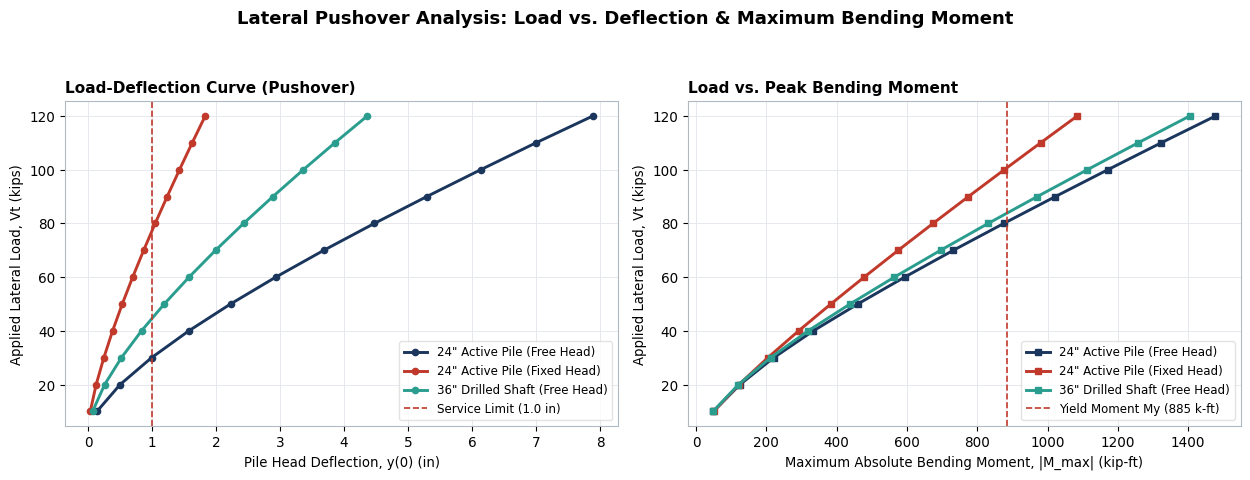

In [6]:
loads = np.linspace(10.0, 120.0, 12)
shaft_36 = build_pile_section({"type": "drilled_shaft", "diameter_in": 36.0, "fc_ksi": 4.0, "cracked_factor": 0.50})

pushovers = {
    f"{pile.diameter_in:.0f}\" Active Pile (Free Head)": run_pushover(pile, PILE_LENGTH_FT, soil, loads, head="free", axial_load_kips=P_AXIAL),
    f"{pile.diameter_in:.0f}\" Active Pile (Fixed Head)": run_pushover(pile, PILE_LENGTH_FT, soil, loads, head="fixed", axial_load_kips=P_AXIAL),
    "36\" Drilled Shaft (Free Head)": run_pushover(shaft_36, PILE_LENGTH_FT, soil, loads, head="free", axial_load_kips=P_AXIAL),
}

cap_rows = []
for name, po in pushovers.items():
    df = po.table
    cap_rows.append({
        "Foundation Option": name,
        "Load at y₀ = 1.0 in (kips)": float(np.interp(1.0, df["head_deflection_in"], df["lateral_load_kips"])),
        "|M_max| at y₀ = 1.0 in (kip-ft)": float(np.interp(1.0, df["head_deflection_in"], df["max_abs_moment_kip_ft"])),
        "y₀ at Vt = 100 kips (in)": float(np.interp(100.0, df["lateral_load_kips"], df["head_deflection_in"])),
        "|M_max| at Vt = 100 kips (kip-ft)": float(np.interp(100.0, df["lateral_load_kips"], df["max_abs_moment_kip_ft"])),
    })
display(pd.DataFrame(cap_rows).set_index("Foundation Option"))

fig = plot_pushover_curves(pushovers, pile=pile, deflection_limit_in=1.0)
plt.show()

## 6. Sand Model Comparison: Reese, Cox & Koop (1974) vs. API RP 2A

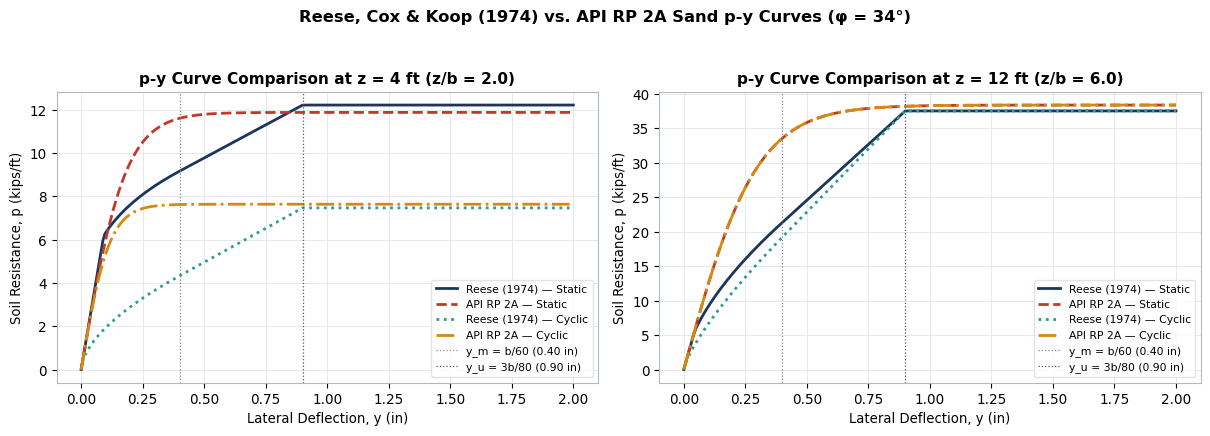

,Head Defl. y₀ (in),Max Moment (kip-ft),Depth M_max (ft),Equil. ∫p dz / Vt
Sand Model,,,,
Reese (1974) Sand — Static,1.20,441.02,8.75,1.00
API RP 2A Sand — Static,0.98,422.13,7.92,1.00
Reese (1974) Sand — Cyclic,1.72,540.67,9.58,1.00


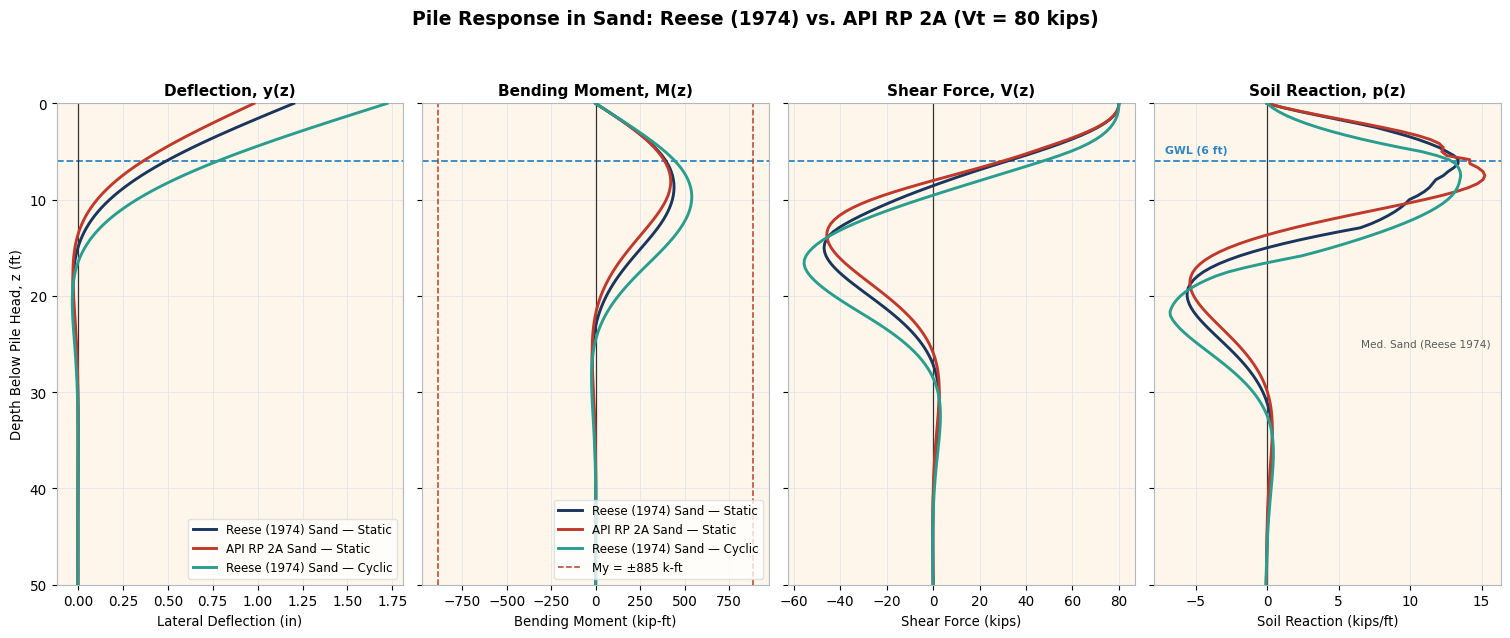

In [7]:
sand_reese_profile = build_soil_profile(
    [{"name": "Med. Sand (Reese 1974)", "type": "reese_sand", "bottom_ft": 65.0, "gamma_pcf": 122.0, "phi_deg": 34.0}],
    gwl_ft=GROUNDWATER_DEPTH_FT,
)
sand_api_profile = build_soil_profile(
    [{"name": "Med. Sand (API RP 2A)", "type": "api_sand", "bottom_ft": 65.0, "gamma_pcf": 122.0, "phi_deg": 34.0}],
    gwl_ft=GROUNDWATER_DEPTH_FT,
)

y_grid = np.linspace(0.0, 2.0, 250)
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))
for ax, z_ft in zip(axes, [4.0, 12.0]):
    for label, prof, ls, col in [
        ("Reese (1974) — Static", sand_reese_profile, "-", "#1B365D"),
        ("API RP 2A — Static", sand_api_profile, "--", "#C0392B"),
        ("Reese (1974) — Cyclic", sand_reese_profile, ":", "#2A9D8F"),
        ("API RP 2A — Cyclic", sand_api_profile, "-.", "#D68910"),
    ]:
        mode = "cyclic" if "Cyclic" in label else "static"
        p_kft = prof.evaluate_py(z_ft, y_grid, pile.diameter_in, loading=mode) * 12.0
        ax.plot(y_grid, p_kft, linestyle=ls, color=col, lw=2.0, label=label)
    ax.axvline(pile.diameter_in / 60.0, color="#888888", ls=":", lw=0.9, label=f"y_m = b/60 ({pile.diameter_in/60:.2f} in)")
    ax.axvline(3 * pile.diameter_in / 80.0, color="#555555", ls=":", lw=0.9, label=f"y_u = 3b/80 ({3*pile.diameter_in/80:.2f} in)")
    ax.set_xlabel("Lateral Deflection, y (in)")
    ax.set_ylabel("Soil Resistance, p (kips/ft)")
    ax.set_title(f"p-y Curve Comparison at z = {z_ft:.0f} ft (z/b = {z_ft*12/pile.diameter_in:.1f})")
    ax.legend(loc="lower right", fontsize=7.8)
fig.suptitle("Reese, Cox & Koop (1974) vs. API RP 2A Sand p-y Curves (φ = 34°)", fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

bc_sand = BoundaryCondition(head="free", lateral_load_kips=80.0, axial_load_kips=P_AXIAL)
sand_comp = {
    "Reese (1974) Sand — Static": solve_lateral_pile(pile, 50.0, sand_reese_profile, bc_sand, loading="static", n_elements=120),
    "API RP 2A Sand — Static": solve_lateral_pile(pile, 50.0, sand_api_profile, bc_sand, loading="static", n_elements=120),
    "Reese (1974) Sand — Cyclic": solve_lateral_pile(pile, 50.0, sand_reese_profile, bc_sand, loading="cyclic", n_elements=120),
}
display(pd.DataFrame([
    {
        "Sand Model": k,
        "Head Defl. y₀ (in)": r.head_deflection_in,
        "Max Moment (kip-ft)": r.max_moment_kip_ft,
        "Depth M_max (ft)": r.depth_max_moment_ft,
        "Equil. ∫p dz / Vt": float(np.trapezoid(r.profile["p_kips_per_ft"], r.profile["z_ft"])) / 80.0,
    }
    for k, r in sand_comp.items()
]).set_index("Sand Model"))

fig = plot_lpile_4panel(sand_comp, soil=sand_reese_profile, pile=pile, title="Pile Response in Sand: Reese (1974) vs. API RP 2A (Vt = 80 kips)")
plt.show()

## 7. Multi-Pile Group & 2D Finite-Element Pile Cap Analysis

Uses your `GROUP_CONFIG` from Section 1 to couple a 2D Euler–Bernoulli concrete pile cap to every pile row with automatic **AASHTO LRFD $p$-multipliers** and axial push-pull $P$-$\Delta$ coupling.

,Cap Lateral Defl (in),Cap Settlement (in),Cap Rotation (mrad),Cap Max |M| (kip-ft),Cap Max |V| (kips),Max Pile |M| (kip-ft),ΣH / H_app,ΣM / M_app
Cap & Joint Design,,,,,,,,
Thick Cap (5.0 ft) — Fixed Heads,0.89,0.18,1.86,4214.17,1030.05,397.86,1.00,1.00
Thin Cap (1.5 ft) — Fixed Heads,0.95,0.27,3.02,2819.41,872.14,586.44,1.00,1.00
Thick Cap (5.0 ft) — Pinned Heads,2.75,0.18,0.87,4150.67,790.60,530.33,1.00,1.00


,x (ft),Piles in Row,p-Multiplier,Connection,Head Defl y₀ (in),Head Axial P (kips/pile),Head Shear V (kips/pile),Row Shear Share (%),Head Moment M₀ (kip-ft),Max |M| (kip-ft/pile),Depth M_max (ft)
Row,,,,,,,,,,,
Row 3 (x=-6.0 ft),-6.00,3,0.30,fixed,0.89,50.93,31.09,25.91,-258.75,258.75,0.00
Row 2 (x=+0.0 ft),0.00,3,0.40,fixed,0.89,205.72,36.15,30.12,-297.90,297.90,0.00
Row 1 (x=+6.0 ft),6.00,3,0.80,fixed,0.89,343.35,52.76,43.97,-397.86,397.86,0.00


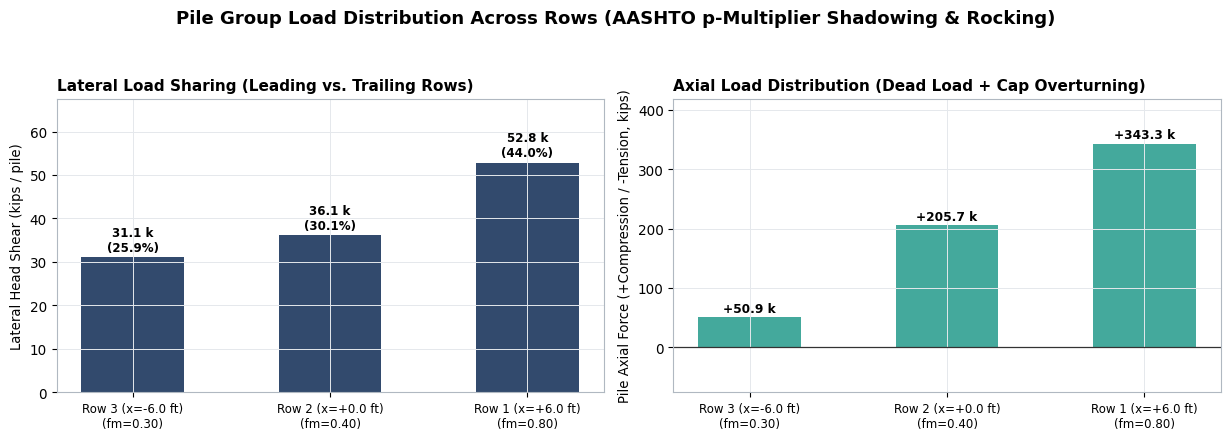

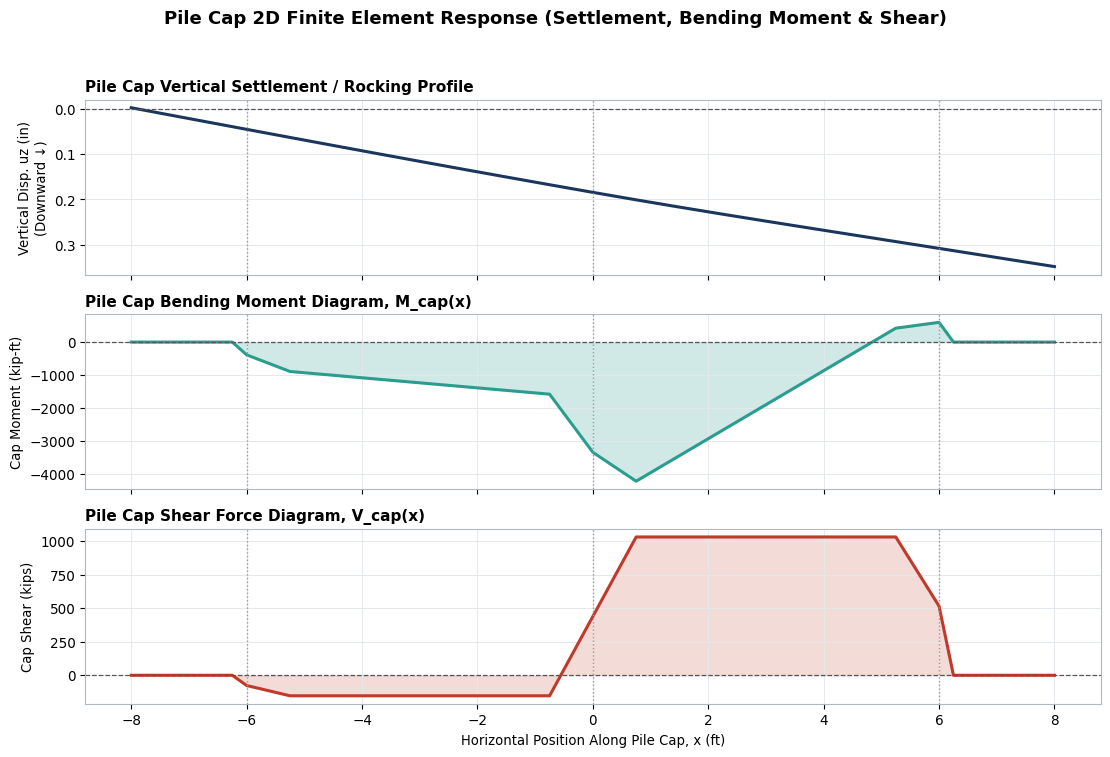

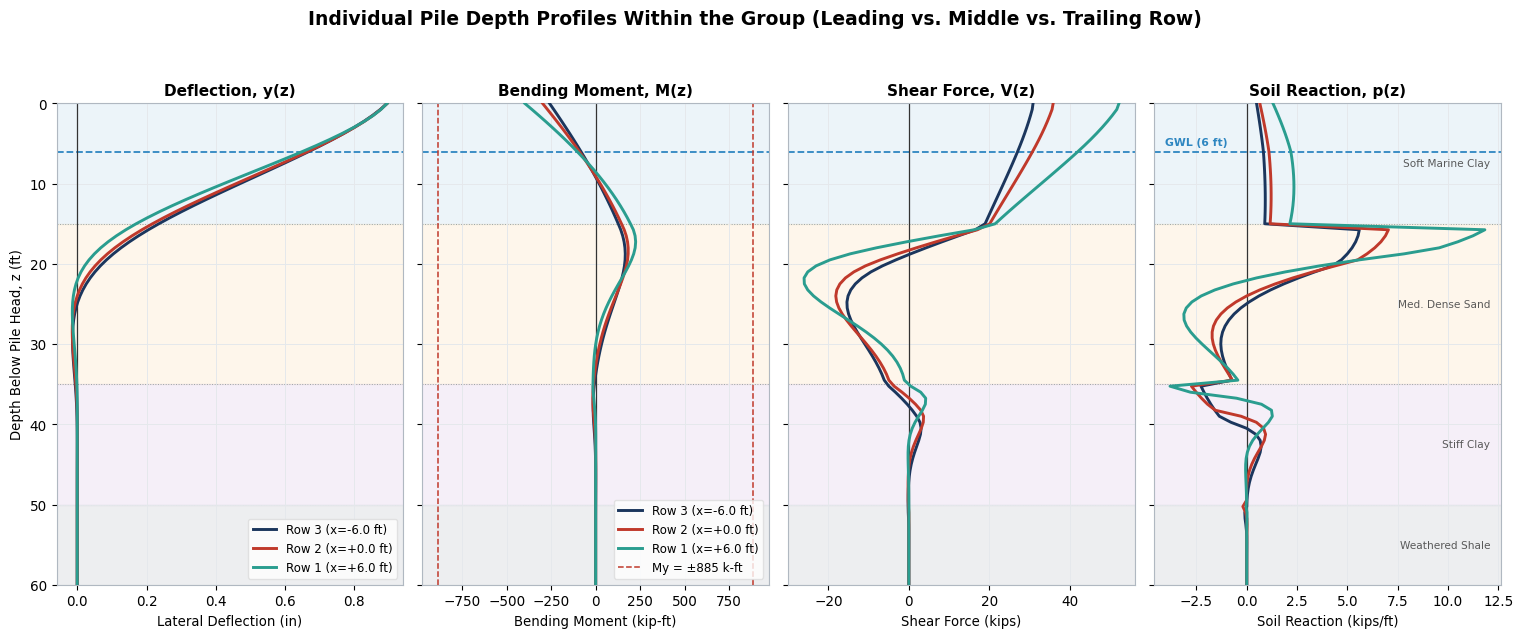

In [8]:
gc = GROUP_CONFIG
cap_loads = CapLoadCase(
    lateral_load_kips=gc["lateral_load_kips"],
    vertical_load_kips=gc["vertical_load_kips"],
    moment_kip_ft=gc["moment_kip_ft"],
    x_load_ft=0.0,
)

piles_fixed = [
    GroupPileSpec(x_ft=x, pile=pile, length_ft=PILE_LENGTH_FT, n_piles_in_row=gc["piles_per_row"], connection="fixed")
    for x in gc["row_x_positions_ft"]
]
piles_pinned = [
    GroupPileSpec(x_ft=x, pile=pile, length_ft=PILE_LENGTH_FT, n_piles_in_row=gc["piles_per_row"], connection="pinned")
    for x in gc["row_x_positions_ft"]
]

cap_thick = PileCapSpec(
    thickness_ft=gc["cap_thickness_ft"], width_ft=gc["cap_width_ft"],
    overhang_ft=gc["cap_overhang_ft"], fc_ksi=gc["cap_fc_ksi"],
)
cap_thin = PileCapSpec(
    thickness_ft=1.5, width_ft=gc["cap_width_ft"],
    overhang_ft=gc["cap_overhang_ft"], fc_ksi=gc["cap_fc_ksi"],
)

grp_thick_fixed  = solve_pile_group(piles_fixed,  cap_thick, soil, cap_loads, n_pile_elements=80)
grp_thin_fixed   = solve_pile_group(piles_fixed,  cap_thin,  soil, cap_loads, n_pile_elements=80)
grp_thick_pinned = solve_pile_group(piles_pinned, cap_thick, soil, cap_loads, n_pile_elements=80)

display(pd.DataFrame([
    {
        "Cap & Joint Design": name,
        "Cap Lateral Defl (in)": r.cap_lateral_defl_in,
        "Cap Settlement (in)": r.cap_vertical_disp_in,
        "Cap Rotation (mrad)": r.cap_rotation_rad * 1000.0,
        "Cap Max |M| (kip-ft)": abs(r.cap_max_moment_kip_ft),
        "Cap Max |V| (kips)": abs(r.cap_max_shear_kips),
        "Max Pile |M| (kip-ft)": r.pile_summary["Max |M| (kip-ft/pile)"].max(),
        "ΣH / H_app": r.equilibrium_check["sum_pile_H_kips"] / cap_loads.lateral_load_kips,
        "ΣM / M_app": r.equilibrium_check["sum_resisting_M_kip_ft"] / cap_loads.moment_kip_ft,
    }
    for name, r in [
        (f"Thick Cap ({gc['cap_thickness_ft']:.1f} ft) — Fixed Heads", grp_thick_fixed),
        ("Thin Cap (1.5 ft) — Fixed Heads", grp_thin_fixed),
        (f"Thick Cap ({gc['cap_thickness_ft']:.1f} ft) — Pinned Heads", grp_thick_pinned),
    ]
]).set_index("Cap & Joint Design"))

display(grp_thick_fixed.pile_summary.set_index("Row"))

fig = plot_group_load_sharing(grp_thick_fixed)
plt.show()

fig = plot_pile_cap_response(grp_thick_fixed)
plt.show()

fig = plot_lpile_4panel(
    grp_thick_fixed.pile_results,
    soil=soil,
    pile=pile,
    title="Individual Pile Depth Profiles Within the Group (Leading vs. Middle vs. Trailing Row)",
)
plt.show()

## 8. Analytical Verification Check (Hetényi 1946 Exact Solution)

In [9]:
ei_v, k0_v, vt_v = 2.0e8, 0.5, 100.0
beta = (k0_v / (4.0 * ei_v)) ** 0.25
pile_v = CustomPileSection(diameter_in=24.0, ei_kip_in2=ei_v)
soil_v = SoilProfile([SoilLayer("Winkler", 0.0, 100.0, 120.0, LinearWinklerSoil(k0_v))])

r_free = solve_lateral_pile(pile_v, 80.0, soil_v, BoundaryCondition(head="free", lateral_load_kips=vt_v), n_elements=200)
r_fix = solve_lateral_pile(pile_v, 80.0, soil_v, BoundaryCondition(head="fixed", lateral_load_kips=vt_v), n_elements=200)

verif = pd.DataFrame([
    ("Free Head: y₀ (in)", r_free.head_deflection_in, vt_v / (2 * ei_v * beta**3)),
    ("Free Head: θ₀ (rad)", r_free.head_slope_rad, -vt_v / (2 * ei_v * beta**2)),
    ("Free Head: M_max (kip-ft)", r_free.max_moment_kip_ft, (vt_v / beta) * np.exp(-np.pi / 4) * np.sin(np.pi / 4) / 12),
    ("Fixed Head: y₀ (in)", r_fix.head_deflection_in, vt_v / (4 * ei_v * beta**3)),
    ("Fixed Head: M₀ (kip-ft)", r_fix.head_moment_kip_ft, -(vt_v / (2 * beta)) / 12),
], columns=["Metric", "FEM Solver", "Hetényi Exact"])
verif["Rel. Error (%)"] = (verif["FEM Solver"] - verif["Hetényi Exact"]).abs() / verif["Hetényi Exact"].abs() * 100.0
display(verif.set_index("Metric"))

,FEM Solver,Hetényi Exact,Rel. Error (%)
Metric,,,
Free Head: y₀ (in),2.00,2.00,0.02
Free Head: θ₀ (rad),-0.01,-0.01,0.02
Free Head: M_max (kip-ft),536.90,537.33,0.08
Fixed Head: y₀ (in),1.00,1.00,0.02
Fixed Head: M₀ (kip-ft),-833.38,-833.33,0.01
